# Notebook 1 · Regresión Logística aplicada a la predicción de lotes defectuosos

**Universidad de Cundinamarca · Especialización en Inteligencia Artificial**
**Curso:** Introducción a Machine Learning (2026-2) · **Docente:** Ing. Wilson Rojas Reales, PhD(c)
**Estudiante:** Juan Pablo Cristancho Tula
**Actividad:** R1-A2-S8 Informe de trabajo – ML Supervisado

---

### Caso de estudio
La empresa manufacturera **XYZ Inc.** quiere predecir si un lote de producción saldrá **defectuoso (1)** o **no defectuoso (0)** a partir de cinco variables del proceso: temperatura, presión, velocidad, horas de operación y vibración.

### Objetivo del notebook
1. Entender el funcionamiento de la regresión logística (función sigmoide, *log-odds*, umbral de decisión).
2. Entrenar el modelo, interpretar sus coeficientes y sus probabilidades.
3. Evaluarlo con matriz de confusión, precisión, recall y F1.
4. Analizar cómo cambia el recall al mover el umbral de decisión, ya que en este caso **un falso negativo (lote defectuoso que llega al cliente) es el error más costoso**.

## 1. Fundamento: la función sigmoide

La regresión logística estima la probabilidad de la clase positiva combinando linealmente las variables y pasando el resultado por la función sigmoide:

$$z = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p \qquad\qquad P(y=1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

El valor $z$ es el **logaritmo de las probabilidades a favor** (*log-odds*): $\ln\!\left(\frac{p}{1-p}\right) = z$. Por eso cada coeficiente $\beta_j$ indica cuánto cambia el *log-odds* cuando $x_j$ aumenta una unidad, y $e^{\beta_j}$ es la **razón de probabilidades** (*odds ratio*). Por defecto, el modelo clasifica como 1 cuando $P(y=1\mid x) \geq 0.5$, es decir, cuando $z \geq 0$.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_predict, LeaveOneOut
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#1f4e79", "#d9822b", "#7f7f7f"

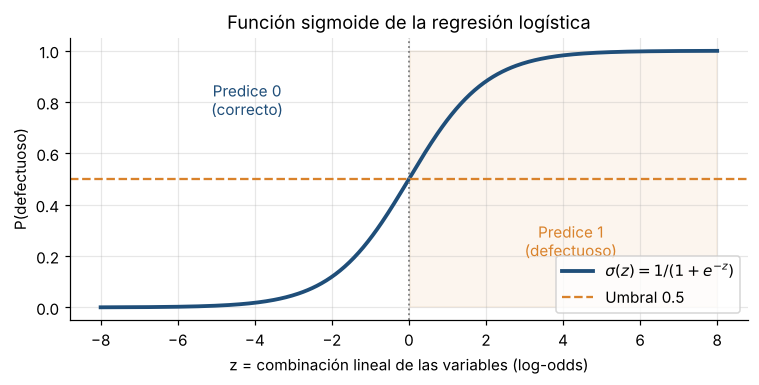

In [2]:
z = np.linspace(-8, 8, 400)
sig = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(z, sig, color=AZUL, lw=2.5, label=r"$\sigma(z)=1/(1+e^{-z})$")
ax.axhline(0.5, color=NARANJA, ls="--", lw=1.5, label="Umbral 0.5")
ax.axvline(0, color=GRIS, ls=":", lw=1.2)
ax.fill_between(z, 0, 1, where=z >= 0, color=NARANJA, alpha=0.08)
ax.text(4.2, 0.2, "Predice 1\n(defectuoso)", ha="center", color=NARANJA)
ax.text(-4.2, 0.75, "Predice 0\n(correcto)", ha="center", color=AZUL)
ax.set_xlabel("z = combinación lineal de las variables (log-odds)")
ax.set_ylabel("P(defectuoso)")
ax.set_title("Función sigmoide de la regresión logística")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figuras/fig01_sigmoide.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. Datos del caso de estudio y análisis exploratorio

In [3]:
data = {
    "temperatura":     [70, 72, 75, 80, 85, 90, 95, 100, 78, 82, 88, 92, 97, 76, 73, 89, 94, 99, 81, 86],
    "presion":         [30, 32, 34, 36, 40, 42, 45, 48, 35, 37, 41, 43, 46, 33, 31, 42, 44, 47, 36, 39],
    "velocidad":       [120, 118, 115, 110, 105, 100, 95, 90, 112, 108, 102, 98, 93, 116, 119, 101, 96, 91, 109, 104],
    "horas_operacion": [2, 3, 4, 6, 8, 10, 12, 14, 5, 7, 9, 11, 13, 4, 3, 10, 12, 15, 6, 8],
    "vibracion":       [1.2, 1.4, 1.6, 2.0, 2.5, 3.0, 3.5, 4.0, 1.8, 2.2, 2.8, 3.2, 3.7, 1.5, 1.3, 3.1, 3.6, 4.2, 2.1, 2.6],
    "defectuoso":      [0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1],
}
df = pd.DataFrame(data)
VARS = ["temperatura", "presion", "velocidad", "horas_operacion", "vibracion"]

print("Dimensiones:", df.shape)
print("Distribución de la variable objetivo:", df["defectuoso"].value_counts().sort_index().to_dict())
df.head()

Dimensiones: (20, 6)
Distribución de la variable objetivo: {0: 9, 1: 11}


,temperatura,presion,velocidad,horas_operacion,vibracion,defectuoso
0,70,30,120,2,1.2,0
1,72,32,118,3,1.4,0
2,75,34,115,4,1.6,0
3,80,36,110,6,2.0,0
4,85,40,105,8,2.5,1


In [4]:
# Estadísticos descriptivos por clase
df.groupby("defectuoso")[VARS].mean().round(2).rename(index={0: "Correcto (0)", 1: "Defectuoso (1)"})

,temperatura,presion,velocidad,horas_operacion,vibracion
defectuoso,,,,,
Correcto (0),76.33,33.78,114.11,4.44,1.68
Defectuoso (1),92.27,43.36,97.73,11.09,3.29


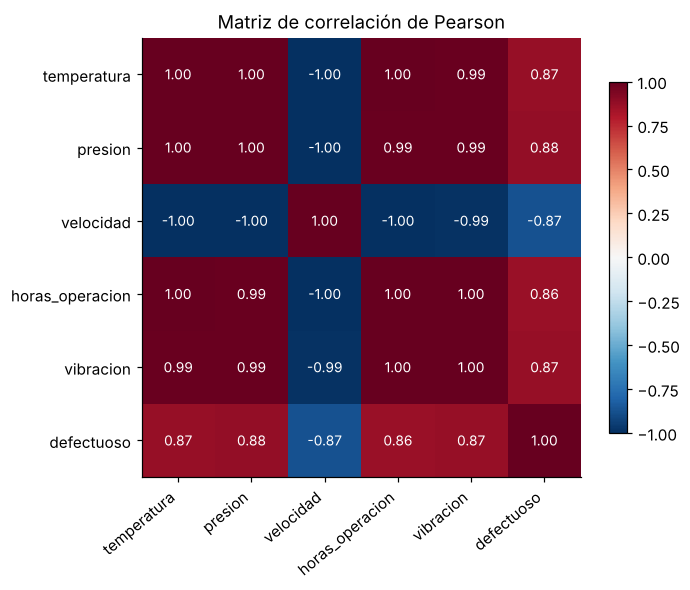

In [5]:
# Matriz de correlación
corr = df.corr().round(2)
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black", fontsize=9)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Matriz de correlación de Pearson")
plt.tight_layout(); plt.savefig("figuras/fig02_correlacion.png", dpi=200, bbox_inches="tight"); plt.show()

**Lectura:** todas las variables tienen una correlación muy alta con la variable objetivo (|r| ≈ 0.86–0.88): temperatura, presión, horas de operación y vibración aumentan el riesgo de defecto, mientras que la velocidad tiene relación inversa. También están **muy correlacionadas entre sí** (multicolinealidad, |r| > 0.97), lo que significa que aportan información casi redundante. Esto hace que el problema sea casi linealmente separable, pero vuelve inestable la interpretación de cada coeficiente por separado.

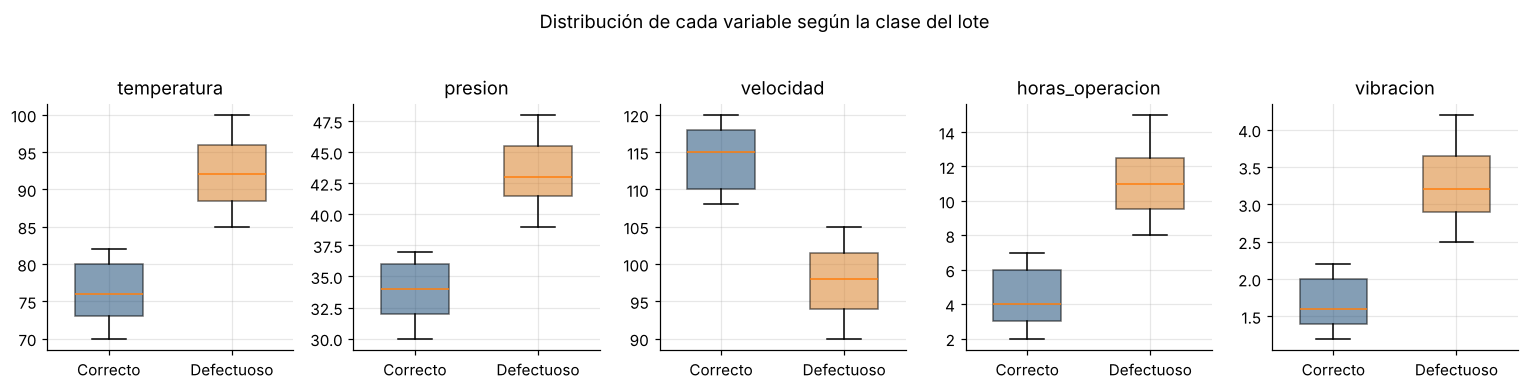

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.4))
for ax, v in zip(axes, VARS):
    grupos = [df.loc[df.defectuoso == c, v] for c in (0, 1)]
    bp = ax.boxplot(grupos, patch_artist=True, widths=0.55)
    for patch, col in zip(bp["boxes"], (AZUL, NARANJA)):
        patch.set_facecolor(col); patch.set_alpha(0.55)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Correcto", "Defectuoso"])
    ax.set_title(v)
fig.suptitle("Distribución de cada variable según la clase del lote", y=1.03)
plt.tight_layout(); plt.savefig("figuras/fig03_boxplots.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Ejercicio A · Regresión logística simple (una variable: vibración)

Antes de usar las cinco variables se entrena un modelo con una sola, para **ver la curva sigmoide ajustada a los datos** y calcular el punto de vibración en el que el modelo cambia de decisión (donde $P = 0.5$, es decir $z = 0 \Rightarrow x^* = -\beta_0/\beta_1$).

Intercepto (β0) = -4.853
Coeficiente vibración (β1) = 2.047
Odds ratio = e^β1 = 7.74  -> por cada unidad adicional de vibración, las probabilidades a favor de defecto se multiplican por 7.74
Vibración frontera (P = 0.5): 2.37


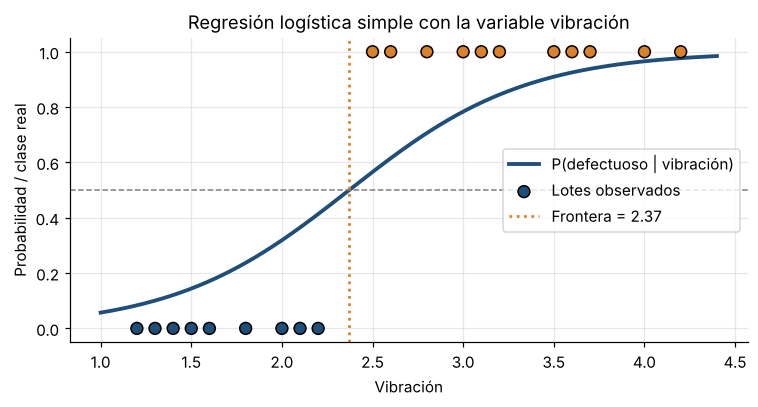

In [7]:
X1 = df[["vibracion"]]
y = df["defectuoso"]
lr1 = LogisticRegression(max_iter=1000).fit(X1, y)
b0, b1 = lr1.intercept_[0], lr1.coef_[0, 0]
umbral_vib = -b0 / b1

print(f"Intercepto (β0) = {b0:.3f}")
print(f"Coeficiente vibración (β1) = {b1:.3f}")
print(f"Odds ratio = e^β1 = {np.exp(b1):.2f}  -> por cada unidad adicional de vibración, las probabilidades a favor de defecto se multiplican por {np.exp(b1):.2f}")
print(f"Vibración frontera (P = 0.5): {umbral_vib:.2f}")

xs = np.linspace(1.0, 4.4, 300).reshape(-1, 1)
ps = lr1.predict_proba(pd.DataFrame(xs, columns=["vibracion"]))[:, 1]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(xs, ps, color=AZUL, lw=2.5, label="P(defectuoso | vibración)")
ax.scatter(df.vibracion, df.defectuoso, c=np.where(df.defectuoso == 1, NARANJA, AZUL),
           s=60, edgecolor="k", zorder=3, label="Lotes observados")
ax.axhline(0.5, color=GRIS, ls="--", lw=1)
ax.axvline(umbral_vib, color=NARANJA, ls=":", lw=1.8, label=f"Frontera = {umbral_vib:.2f}")
ax.set_xlabel("Vibración"); ax.set_ylabel("Probabilidad / clase real")
ax.set_title("Regresión logística simple con la variable vibración")
ax.legend(loc="center right")
plt.tight_layout(); plt.savefig("figuras/fig04_logistica_simple.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretación:** el coeficiente positivo indica que a mayor vibración, mayor probabilidad de defecto. La frontera se ubica entre 2.2 (último lote correcto observado con vibración más alta) y 2.5 (primer lote defectuoso), justo donde los datos cambian de clase. Con solo esta variable el modelo ya separa casi por completo los lotes, lo que confirma lo observado en la matriz de correlación.

## 4. Ejercicio B · Regresión logística multivariable

Se usan las cinco variables, con la misma partición del script de la guía (70 % entrenamiento, 30 % prueba, `stratify=y`, `random_state=42`). Se añade **estandarización** (`StandardScaler`) dentro de un `Pipeline` porque las variables tienen escalas muy distintas (velocidad ≈ 100, vibración ≈ 2). Esto mejora la convergencia del optimizador, hace comparables los coeficientes y evita fuga de información, ya que el escalador se ajusta solo con los datos de entrenamiento.

In [8]:
X = df[VARS]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Clases en prueba:", y_test.value_counts().sort_index().to_dict())

modelo_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo_lr.fit(X_train, y_train)

Entrenamiento: (14, 5) | Prueba: (6, 5)
Clases en prueba: {0: 3, 1: 3}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['temperatura','presion','velocidad','horas_operacion','vibracion']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [9]:
lr = modelo_lr.named_steps["logisticregression"]
coef = pd.DataFrame({
    "Variable": VARS,
    "Coeficiente (β, estandarizado)": lr.coef_[0].round(3),
    "Odds ratio (e^β)": np.exp(lr.coef_[0]).round(2),
}).sort_values("Coeficiente (β, estandarizado)", key=abs, ascending=False)
print(f"Intercepto: {lr.intercept_[0]:.3f}")
coef

Intercepto: 0.687


,Variable,"Coeficiente (β, estandarizado)",Odds ratio (e^β)
1,presion,0.714,2.04
0,temperatura,0.642,1.90
2,velocidad,-0.635,0.53
4,vibracion,0.625,1.87
3,horas_operacion,0.587,1.80


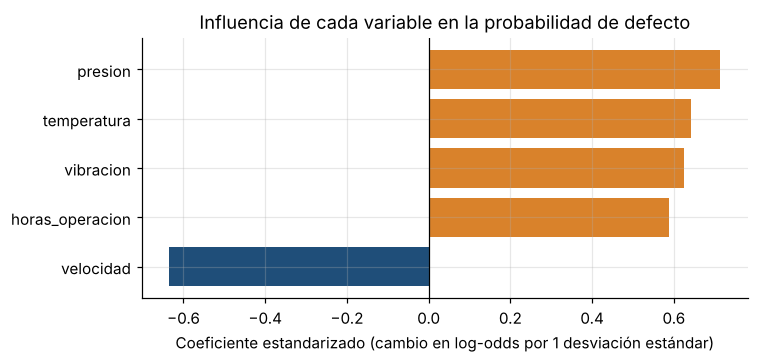

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.4))
orden = coef.sort_values("Coeficiente (β, estandarizado)")
cols = [NARANJA if c > 0 else AZUL for c in orden["Coeficiente (β, estandarizado)"]]
ax.barh(orden["Variable"], orden["Coeficiente (β, estandarizado)"], color=cols)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Coeficiente estandarizado (cambio en log-odds por 1 desviación estándar)")
ax.set_title("Influencia de cada variable en la probabilidad de defecto")
plt.tight_layout(); plt.savefig("figuras/fig05_coeficientes.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretación de los coeficientes:** un coeficiente positivo (naranja) aumenta la probabilidad de defecto y uno negativo (azul) la reduce. Como las variables están estandarizadas, el coeficiente indica el cambio en *log-odds* cuando la variable sube una desviación estándar. Por la multicolinealidad, el modelo reparte el efecto entre las cinco variables y sus magnitudes son parecidas; por eso la conclusión práctica es **conjunta**: los lotes con alta temperatura, presión, vibración y horas de uso, y con baja velocidad, son los de mayor riesgo.

## 5. Probabilidades y predicciones en el conjunto de prueba

In [11]:
proba = modelo_lr.predict_proba(X_test)[:, 1]
y_pred = modelo_lr.predict(X_test)
tabla = X_test.copy()
tabla["P(defectuoso)"] = proba.round(3)
tabla["Predicción"] = y_pred
tabla["Real"] = y_test.values
tabla["¿Acierta?"] = np.where(tabla["Predicción"] == tabla["Real"], "Sí", "No")
tabla.sort_values("P(defectuoso)")

,temperatura,presion,velocidad,horas_operacion,vibracion,P(defectuoso),Predicción,Real,¿Acierta?
13,76,33,116,4,1.5,0.066,0,0,Sí
8,78,35,112,5,1.8,0.162,0,0,Sí
3,80,36,110,6,2.0,0.275,0,0,Sí
15,89,42,101,10,3.1,0.911,1,1,Sí
6,95,45,95,12,3.5,0.983,1,1,Sí
12,97,46,93,13,3.7,0.991,1,1,Sí


## 6. Evaluación: matriz de confusión y métricas

TN = 3 | FP = 0 | FN = 0 | TP = 3

Accuracy  = 1.000
Precision = 1.000
Recall    = 1.000
F1-score  = 1.000
ROC-AUC   = 1.000

              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



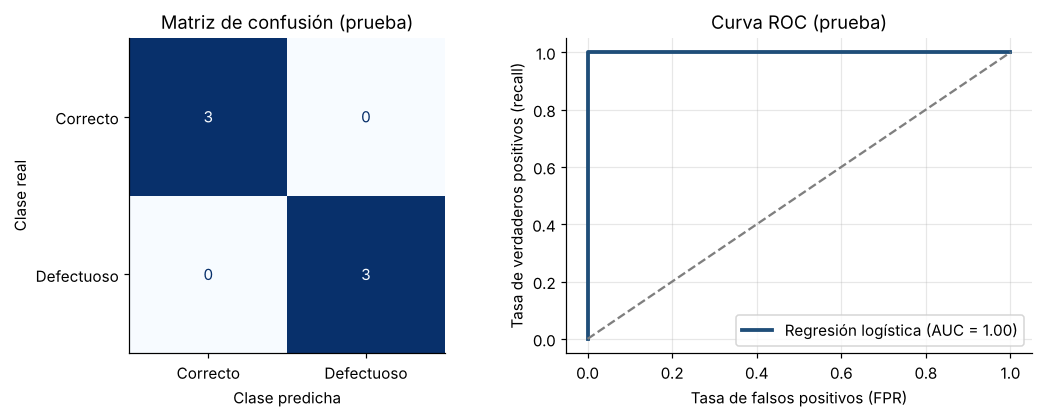

In [12]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}\n")
print(f"Accuracy  = {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision = {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall    = {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score  = {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC   = {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["Correcto", "Defectuoso"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
ConfusionMatrixDisplay(cm, display_labels=["Correcto", "Defectuoso"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (prueba)"); axes[0].grid(False)
axes[0].set_xlabel("Clase predicha"); axes[0].set_ylabel("Clase real")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color=AZUL, lw=2.5, label=f"Regresión logística (AUC = {roc_auc_score(y_test, proba):.2f})")
axes[1].set_xlabel("Tasa de falsos positivos (FPR)"); axes[1].set_ylabel("Tasa de verdaderos positivos (recall)"); axes[1].legend(loc="lower right")
axes[1].plot([0, 1], [0, 1], ls="--", color=GRIS)
axes[1].set_title("Curva ROC (prueba)")
plt.tight_layout(); plt.savefig("figuras/fig06_lr_matriz_roc.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretación:** el modelo clasifica correctamente los 6 lotes de prueba (3 correctos y 3 defectuosos): no hay falsos positivos ni falsos negativos, por lo que todas las métricas valen 1.0. Este resultado es coherente con lo visto en el análisis exploratorio (clases casi linealmente separables), pero **6 lotes son una muestra muy pequeña** para afirmar que el modelo es perfecto: un solo error cambiaría el accuracy a 0.83. Por eso, a continuación se valida con todos los datos mediante *Leave-One-Out*.

## 7. Ejercicio C · Ajuste del umbral para priorizar el recall

En este caso el costo de un **falso negativo** (lote defectuoso que pasa como correcto y llega al cliente) es mayor que el de un **falso positivo** (inspección adicional de un lote que estaba bien). La regresión logística permite **bajar el umbral de decisión** para detectar más defectos a cambio de más alarmas falsas.

Para analizarlo con más datos que los 6 de prueba, se obtienen probabilidades **fuera de muestra** de los 20 lotes con validación cruzada *Leave-One-Out* (cada lote se predice con un modelo que no lo vio en el entrenamiento).

In [13]:
proba_loo = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                              X, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]

filas = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba_loo >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y, p).ravel()
    filas.append({"Umbral": t, "TP": tp_, "FN": fn_, "FP": fp_, "TN": tn_,
                  "Precision": round(precision_score(y, p, zero_division=0), 3),
                  "Recall": round(recall_score(y, p, zero_division=0), 3),
                  "F1": round(f1_score(y, p, zero_division=0), 3)})
tabla_umbral = pd.DataFrame(filas)
tabla_umbral

,Umbral,TP,FN,FP,TN,Precision,Recall,F1
0,0.2,11,0,3,6,0.786,1.000,0.880
1,0.3,11,0,1,8,0.917,1.000,0.957
2,0.4,11,0,1,8,0.917,1.000,0.957
3,0.5,11,0,0,9,1.000,1.000,1.000
4,0.6,11,0,0,9,1.000,1.000,1.000
5,0.7,9,2,0,9,1.000,0.818,0.900
6,0.8,9,2,0,9,1.000,0.818,0.900


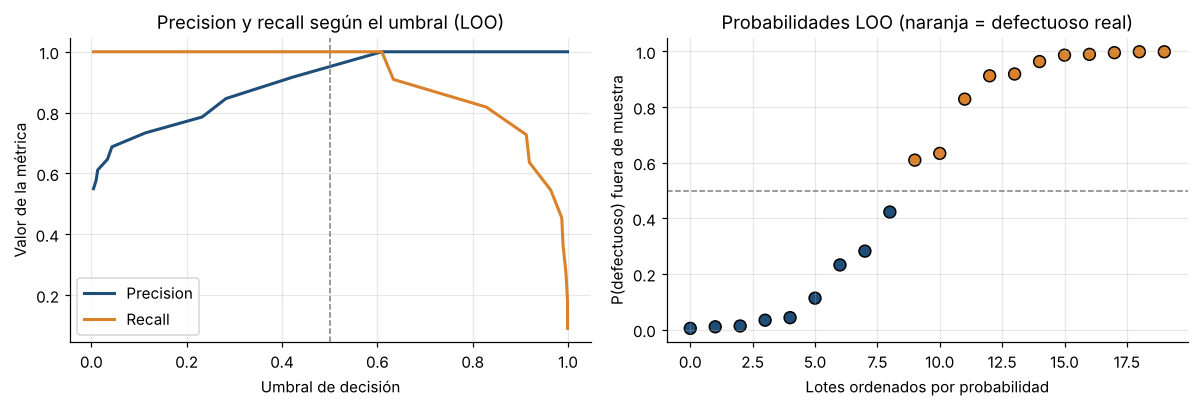

In [14]:
prec, rec, thr = precision_recall_curve(y, proba_loo)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(thr, prec[:-1], color=AZUL, lw=2, label="Precision")
axes[0].plot(thr, rec[:-1], color=NARANJA, lw=2, label="Recall")
axes[0].axvline(0.5, color=GRIS, ls="--", lw=1)
axes[0].set_xlabel("Umbral de decisión"); axes[0].set_ylabel("Valor de la métrica")
axes[0].set_title("Precision y recall según el umbral (LOO)"); axes[0].legend()

orden = np.argsort(proba_loo)
axes[1].scatter(range(20), proba_loo[orden], c=np.where(y.values[orden] == 1, NARANJA, AZUL), s=60, edgecolor="k")
axes[1].axhline(0.5, color=GRIS, ls="--", lw=1)
axes[1].set_xlabel("Lotes ordenados por probabilidad"); axes[1].set_ylabel("P(defectuoso) fuera de muestra")
axes[1].set_title("Probabilidades LOO (naranja = defectuoso real)")
plt.tight_layout(); plt.savefig("figuras/fig07_umbral.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretación:** con las probabilidades fuera de muestra, los umbrales entre 0.5 y 0.6 separan perfectamente los 20 lotes. Al **bajar** el umbral a 0.3–0.4 el recall se mantiene en 1.0 pero aparece 1 falso positivo (un lote correcto enviado a revisión), y con 0.2 aparecen 3. Al **subir** el umbral a 0.7 o más se pierden 2 lotes defectuosos (2 falsos negativos) y el recall cae a 0.818: este es el escenario que la empresa debe evitar. En planta, con más datos y ruido, se recomendaría trabajar con un umbral igual o ligeramente inferior a 0.5, porque un falso positivo cuesta una inspección, mientras que un falso negativo cuesta una devolución.

## 8. Ejercicio D · Uso del modelo con lotes nuevos

Se simulan tres lotes **hipotéticos** (no forman parte del dataset) para mostrar cómo se usaría el modelo en planta: uno con condiciones normales, uno en la zona de frontera y uno con condiciones de riesgo.

In [15]:
nuevos = pd.DataFrame({
    "temperatura":     [74, 84, 96],
    "presion":         [32, 38, 46],
    "velocidad":       [117, 106, 94],
    "horas_operacion": [3, 7, 13],
    "vibracion":       [1.4, 2.4, 3.8],
}, index=["Lote A (normal)", "Lote B (frontera)", "Lote C (riesgo)"])

nuevos["P(defectuoso)"] = modelo_lr.predict_proba(nuevos[VARS])[:, 1].round(3)
nuevos["Decisión (umbral 0.5)"] = np.where(nuevos["P(defectuoso)"] >= 0.5, "Defectuoso → revisar", "Correcto → liberar")
nuevos["Decisión (umbral 0.3)"] = np.where(nuevos["P(defectuoso)"] >= 0.3, "Defectuoso → revisar", "Correcto → liberar")
nuevos

,temperatura,presion,velocidad,horas_operacion,vibracion,P(defectuoso),Decisión (umbral 0.5),Decisión (umbral 0.3)
Lote A (normal),74,32,117,3,1.4,0.039,Correcto → liberar,Correcto → liberar
Lote B (frontera),84,38,106,7,2.4,0.558,Defectuoso → revisar,Defectuoso → revisar
Lote C (riesgo),96,46,94,13,3.8,0.991,Defectuoso → revisar,Defectuoso → revisar


## 9. Conclusiones del notebook

* La regresión logística transforma una combinación lineal de las variables en una probabilidad mediante la función sigmoide; los coeficientes se interpretan en términos de *log-odds* y *odds ratio*.
* En el caso de producción, todas las variables están fuertemente asociadas al defecto (temperatura, presión, horas y vibración en forma directa; velocidad en forma inversa) y son muy colineales entre sí.
* El modelo obtuvo accuracy, precision, recall y F1 de 1.0 en el conjunto de prueba y separó perfectamente los 20 lotes con *Leave-One-Out*. Sin embargo, el dataset tiene solo 20 registros, por lo que estos valores **no garantizan el mismo desempeño en producción**.
* La principal ventaja práctica del modelo es que entrega **probabilidades interpretables** y permite ajustar el umbral para priorizar el recall, que es la métrica clave cuando el objetivo es que ningún lote defectuoso llegue al cliente.